In [29]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as sps

In [30]:
def explicit_euler(h, p_0, q_0):
    t_vals = np.arange(0, 20 + h, h)

    p_vals = np.zeros(t_vals.shape)
    q_vals = np.zeros(t_vals.shape)
    E_vals = np.zeros(t_vals.shape)

    p_vals[0] = p_0
    q_vals[0] = q_0

    
    for i in range(1, len(t_vals)):
        p_vals[i] = p_vals[i-1] + h * -np.sin(q_vals[i-1])
        q_vals[i] = q_vals[i-1] + h * p_vals[i-1]

    for i in range(len(t_vals)):
        E_vals[i] = (p_vals[i] ** 2) / 2 + (1 - np.cos(q_vals[i]))

    return t_vals, p_vals, q_vals, E_vals


Text(0.5, 0, 'Time')

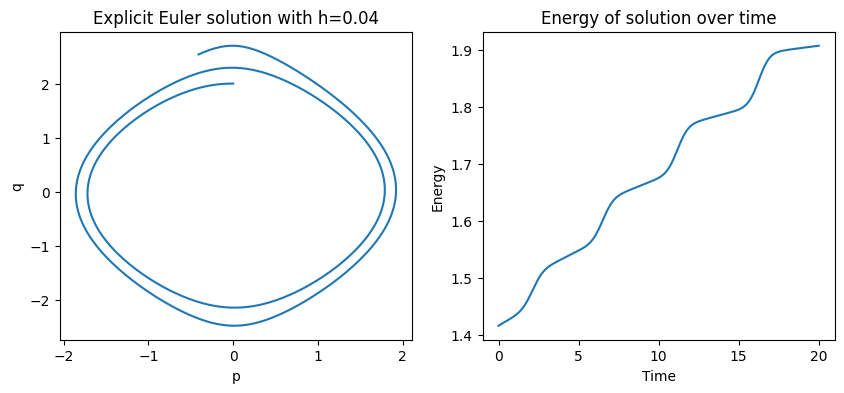

In [31]:
t_vals, p_vals, q_vals, E_vals = explicit_euler(h=0.04, p_0=0, q_0=2)

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Explicit Euler solution with h=0.04')
ax1.plot(p_vals, q_vals)

ax2.plot(t_vals, E_vals)
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')


Text(0.5, 0, 'Time')

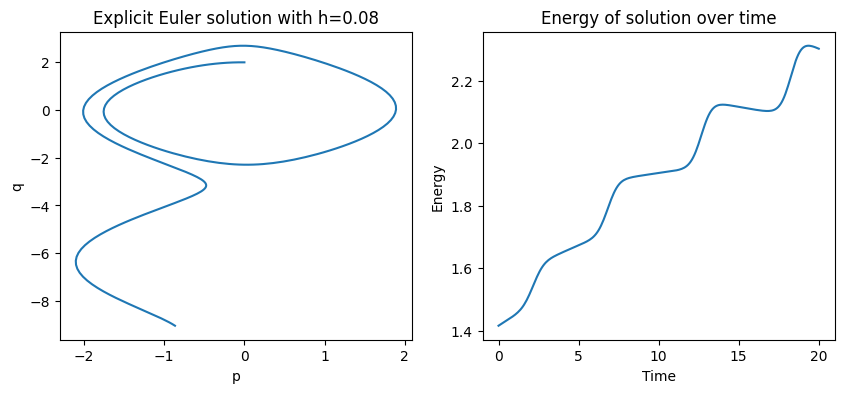

In [32]:

t_vals, p_vals, q_vals, E_vals = explicit_euler(h=0.08, p_0=0, q_0=2)

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Explicit Euler solution with h=0.08')
ax1.plot(p_vals, q_vals)

ax2.plot(t_vals, E_vals)
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')


In [33]:
def structure_preserving_euler(h, p_0, q_0, T):
    t_vals = np.arange(0, T + h, h)

    p_vals = np.zeros(t_vals.shape)
    q_vals = np.zeros(t_vals.shape)
    E_vals = np.zeros(t_vals.shape)
    E_num_vals = np.zeros(t_vals.shape)


    p_vals[0] = p_0
    q_vals[0] = q_0

    
    for i in range(1, len(t_vals)):
        q_vals[i] = q_vals[i-1] + h * p_vals[i-1]
        p_vals[i] = p_vals[i-1] - h * np.sin(q_vals[i])

    for i in range(len(t_vals)):
        E_vals[i] = (p_vals[i] ** 2) / 2 + (1 - np.cos(q_vals[i]))

        E_num_vals[i] = (p_vals[i] ** 2) / 2 + (1/2 * h * p_vals[i] * np.sin(q_vals[i])) + (1 - np.cos(q_vals[i]))

    return t_vals, p_vals, q_vals, E_vals, E_num_vals

Text(0.5, 0, 'Time')

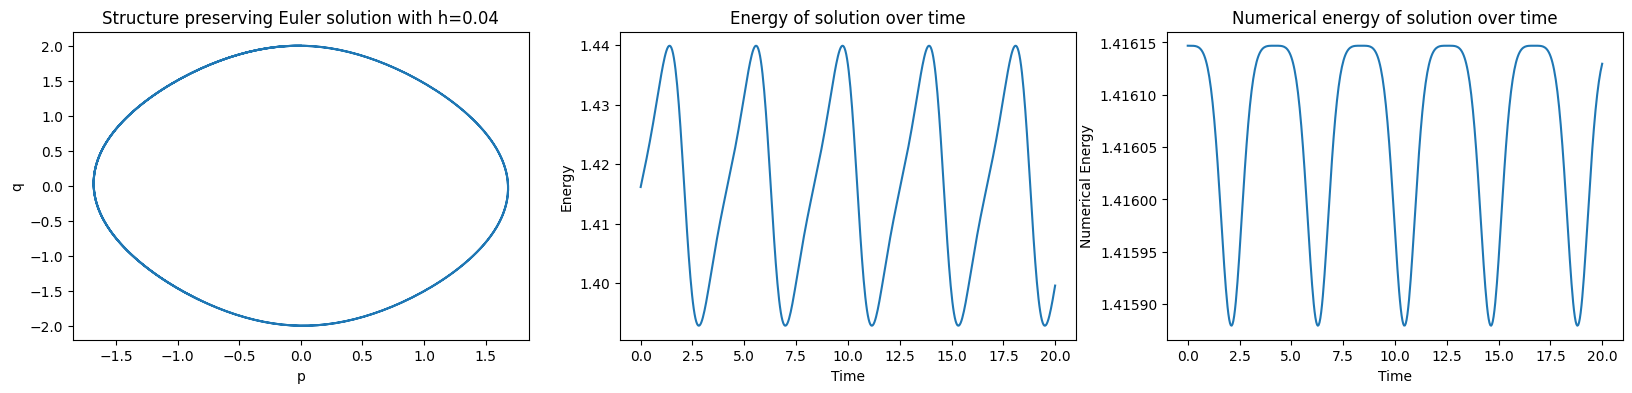

In [34]:
t_vals, p_vals, q_vals, E_vals, E_num_vals = structure_preserving_euler(h=0.04, p_0=0, q_0=2, T=20)

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(20, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Structure preserving Euler solution with h=0.04')
ax1.plot(p_vals, q_vals)

ax2.plot(t_vals, E_vals)
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')

ax3.plot(t_vals, E_num_vals)
ax3.set_title('Numerical energy of solution over time')
ax3.set_ylabel('Numerical Energy')
ax3.set_xlabel('Time')

Text(0.5, 0, 'Time')

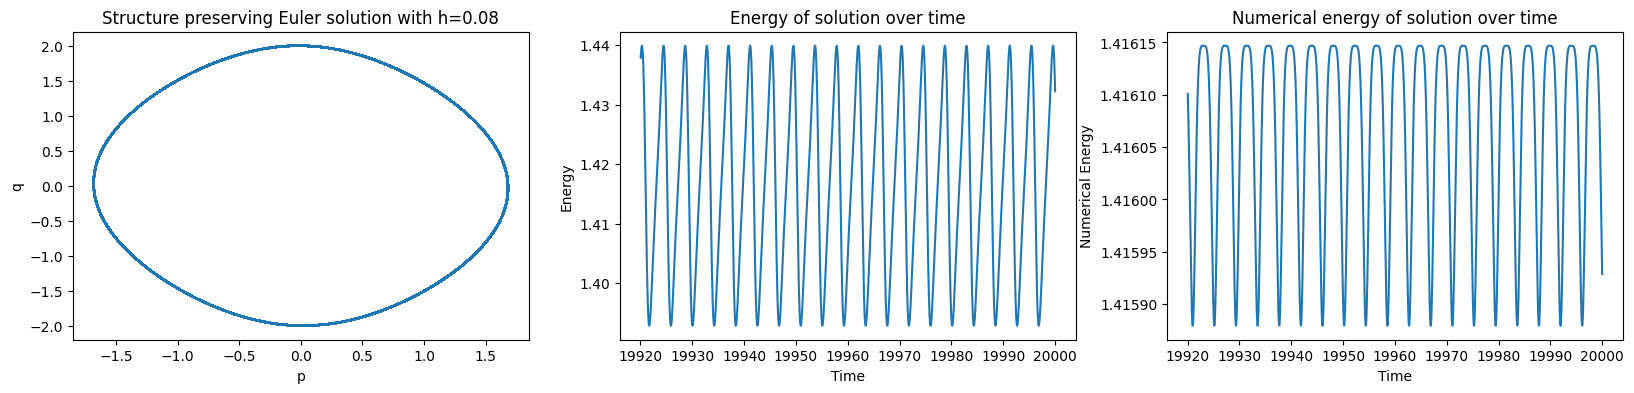

In [35]:
t_vals, p_vals, q_vals, E_vals, E_num_vals = structure_preserving_euler(h=0.04, p_0=0, q_0=2, T=20000)

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(20, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Structure preserving Euler solution with h=0.08')
ax1.plot(p_vals, q_vals)

K = 2000

ax2.plot(t_vals[-K:], E_vals[-K:])
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')

ax3.plot(t_vals[-K:], E_num_vals[-K:])
ax3.set_title('Numerical energy of solution over time')
ax3.set_ylabel('Numerical Energy')
ax3.set_xlabel('Time')

In [36]:
def modified_euler(h, p_0, q_0, T):
    t_vals = np.arange(0, T + h, h)

    p_vals = np.zeros(t_vals.shape)
    q_vals = np.zeros(t_vals.shape)
    E_vals = np.zeros(t_vals.shape)

    p_vals[0] = p_0
    q_vals[0] = q_0

    
    for i in range(1, len(t_vals)):
        
        p_vals[i] = p_vals[i-1] - 1/2 * h * np.sin(q_vals[i-1]) - 1/2 * h * np.sin(q_vals[i-1] + h * p_vals[i-1])
        q_vals[i] = q_vals[i-1] + 1/2 * h * p_vals[i-1] + 1/2 * h * (p_vals[i-1] - h * np.sin(q_vals[i-1]))

    for i in range(len(t_vals)):
        E_vals[i] = (p_vals[i] ** 2) / 2 + (1 - np.cos(q_vals[i]))

    return t_vals, p_vals, q_vals, E_vals

Text(0.5, 0, 'Time')

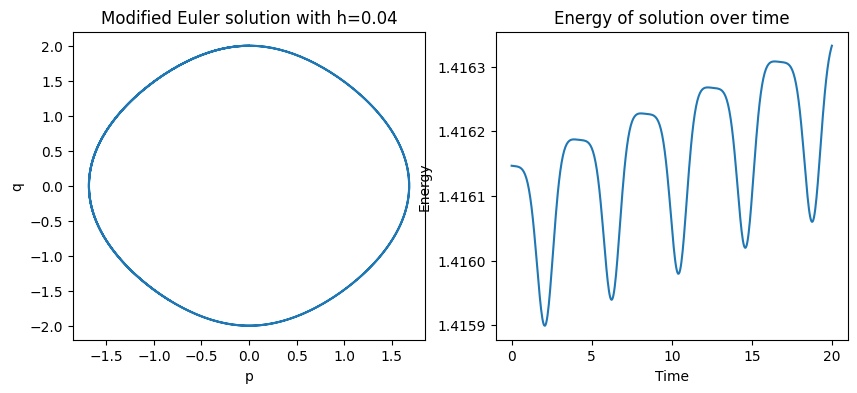

In [37]:
t_vals, p_vals, q_vals, E_vals = modified_euler(h=0.04, p_0=0, q_0=2, T=20)

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Modified Euler solution with h=0.04')
ax1.plot(p_vals, q_vals)

ax2.plot(t_vals, E_vals)
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')

Text(0.5, 0, 'Time')

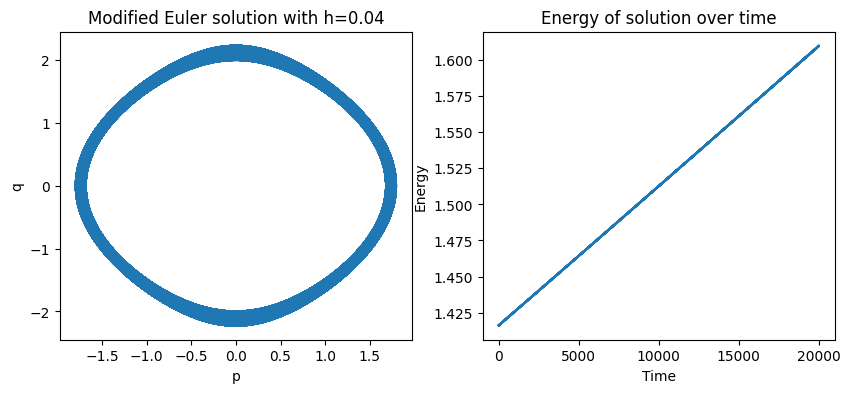

In [38]:
t_vals, p_vals, q_vals, E_vals = modified_euler(h=0.04, p_0=0, q_0=2, T=20000)

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Modified Euler solution with h=0.04')
ax1.plot(p_vals, q_vals)

ax2.plot(t_vals, E_vals)
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')

Text(0.5, 0, 'Time')

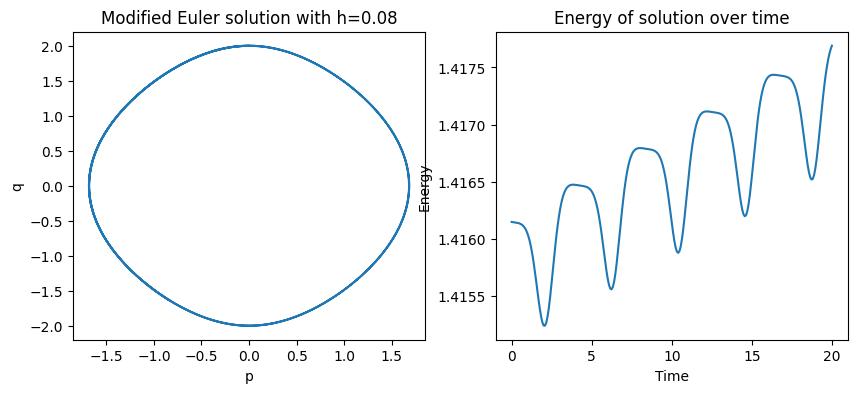

In [39]:
t_vals, p_vals, q_vals, E_vals = modified_euler(h=0.08, p_0=0, q_0=2, T=20)

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Modified Euler solution with h=0.08')
ax1.plot(p_vals, q_vals)

ax2.plot(t_vals, E_vals)
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')

In [40]:
def newtons_method(F, F_prime, x_0):
    x_prev = x_0
    x_next = x_0 - F(x_0)/F_prime(x_0)

    while (np.abs(x_prev - x_next) > 1e-5):
        x_prev = x_next
        x_next = x_prev - F(x_prev)/F_prime(x_prev)

    return x_next


In [41]:
# implicit midpoint method

def implicit_midpoint(h, p_0, q_0, T):
    t_vals = np.arange(0, T + h, h)

    p_vals = np.zeros(t_vals.shape)
    q_vals = np.zeros(t_vals.shape)
    E_vals = np.zeros(t_vals.shape)
    E_num_vals = np.zeros(t_vals.shape)


    k_q = 0
    p_vals[0] = p_0
    q_vals[0] = q_0

    def F(k_q):
        return k_q - h * p_vals[i-1] + 1/2 * (h**2) * np.sin(q_vals[i-1] + k_q/2)

    def F_prime(k_q):
        return 1 + 1/4 * (h**2) * np.cos(q_vals[i-1] + k_q/2)
    
    for i in range(1, len(t_vals)):

        k_q = newtons_method(F, F_prime, h * p_vals[i-1])
        k_p = -h * np.sin(q_vals[i-1] + k_q/2)

        p_vals[i] = p_vals[i-1] + k_p
        q_vals[i] = q_vals[i-1] + k_q

    for i in range(len(t_vals)):
        E_vals[i] = (p_vals[i] ** 2) / 2 + (1 - np.cos(q_vals[i]))
        E_num_vals[i] = (p_vals[i] ** 2) / 2 + (1/2 * h * p_vals[i] * np.sin(q_vals[i])) + (1 - np.cos(q_vals[i]))

    return t_vals, p_vals, q_vals, E_vals, E_num_vals

Text(0.5, 0, 'Time')

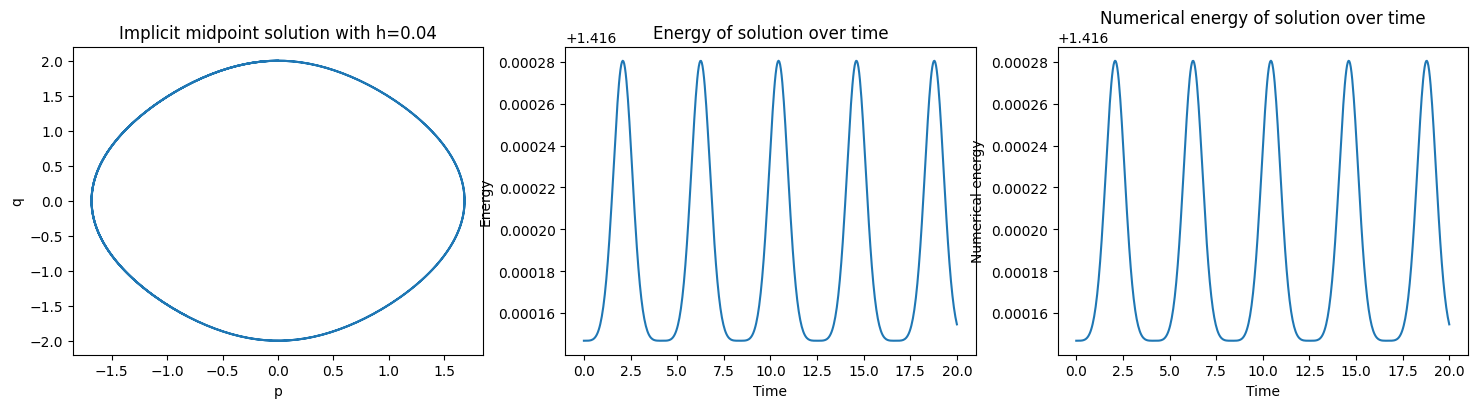

In [42]:
t_vals, p_vals, q_vals, E_vals, E_num_vals = implicit_midpoint(h=0.04, p_0=0, q_0=2, T=20)

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(18, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Implicit midpoint solution with h=0.04')
ax1.plot(p_vals, q_vals)

ax2.plot(t_vals, E_vals)
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')

ax3.plot(t_vals, E_vals)
ax3.set_title('Numerical energy of solution over time')
ax3.set_ylabel('Numerical energy')
ax3.set_xlabel('Time')

Text(0.5, 0, 'Time')

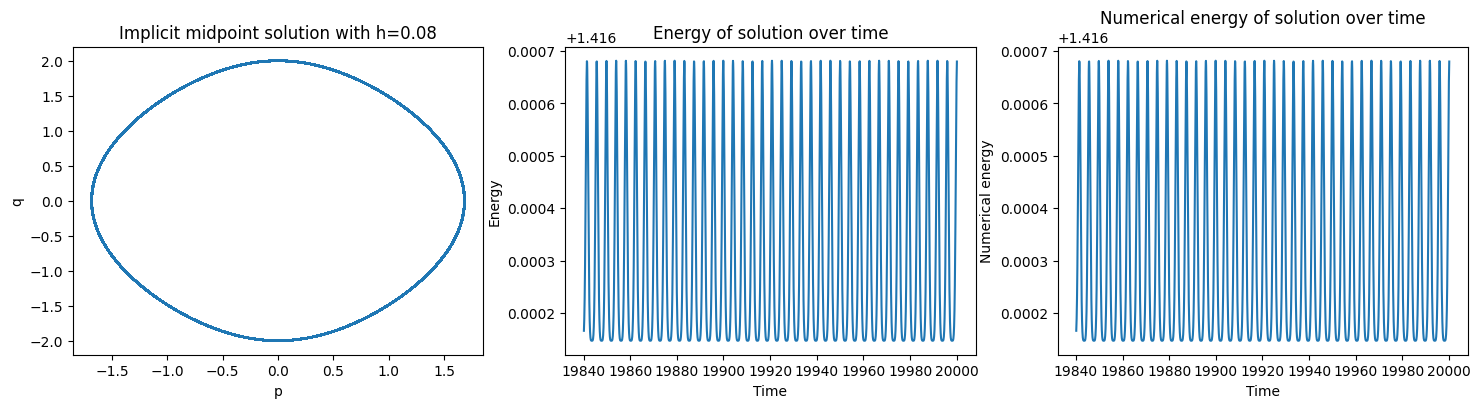

In [43]:
t_vals, p_vals, q_vals, E_vals, E_num_vals = implicit_midpoint(h=0.08, p_0=0, q_0=2, T=20000)

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(18, 4))
ax1.set_xlabel('p')
ax1.set_ylabel('q')
ax1.set_title('Implicit midpoint solution with h=0.08')
ax1.plot(p_vals, q_vals)

K = 2000

ax2.plot(t_vals[-K:], E_vals[-K:])
ax2.set_title('Energy of solution over time')
ax2.set_ylabel('Energy')
ax2.set_xlabel('Time')

ax3.plot(t_vals[-K:], E_vals[-K:])
ax3.set_title('Numerical energy of solution over time')
ax3.set_ylabel('Numerical energy')
ax3.set_xlabel('Time')

In [44]:
def multistep_a(h, p_0, q_0, T):
    t_vals = np.arange(0, T + h, h)
    q_vals = np.zeros(t_vals.shape)
    p_vals = np.zeros(t_vals.shape)


    # init
    p_vals[0] = p_0
    q_vals[0] = q_0

    for i in range(1, 2):
            p_vals[i] = p_vals[i-1] - 1/2 * h * np.sin(q_vals[i-1]) - 1/2 * h * np.sin(q_vals[i-1] + h * p_vals[i-1])
            q_vals[i] = q_vals[i-1] + 1/2 * h * p_vals[i-1] + 1/2 * h * (p_vals[i-1] - h * np.sin(q_vals[i-1]))

    # multistep
    for i in range(2, len(t_vals)):
        q_vals[i] = 2 * q_vals[i-1] - q_vals[i-2] - (h ** 2) * np.sin(q_vals[i-1])

    return t_vals, p_vals, q_vals

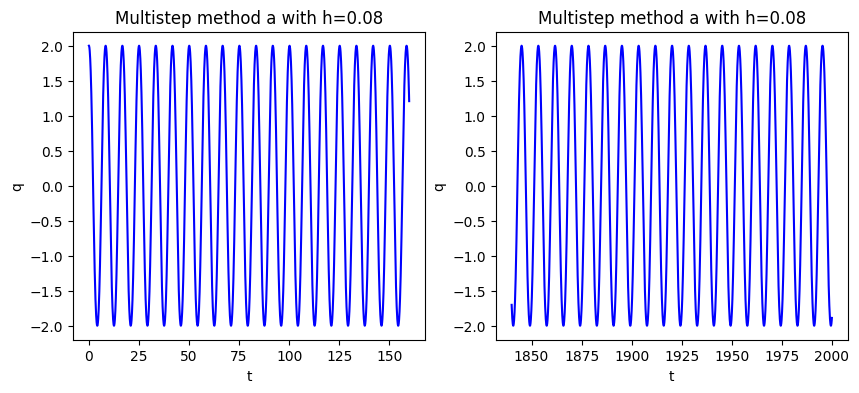

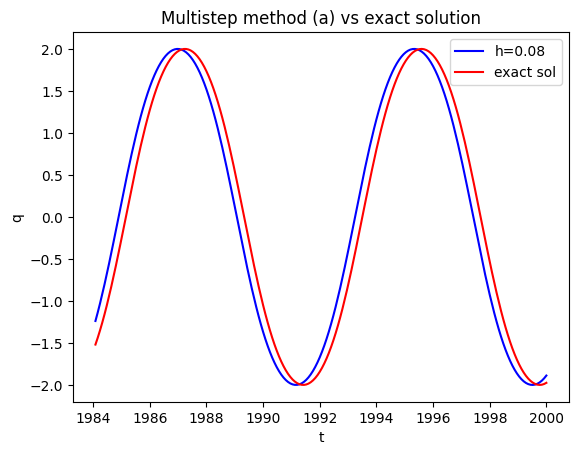

In [45]:
t_vals, p_vals, q_vals = multistep_a(h=0.08, p_0=0, q_0=2, T=2000)

K1 = 2000

fig, (ax1, ax2) = plt.subplots(ncols=2, nrows=1, figsize=(10,4))
ax1.set_xlabel('t')
ax1.set_ylabel('q')
ax1.set_title('Multistep method a with h=0.08')
ax1.plot(t_vals[:K1], q_vals[:K1], color='blue')

ax2.set_xlabel('t')
ax2.set_ylabel('q')
ax2.set_title('Multistep method a with h=0.08')
ax2.plot(t_vals[-K1:], q_vals[-K1:], color='blue')


K2 = -200

# computing exact solution
k = np.sin(1)
m = k**2 
sn, cn, dn, _ = sps.ellipj(t_vals, m)
cd = cn / dn
q_exact = 2 * np.arcsin(k * cd)
p_exact = -2 * k * (1 - m) * sn / (dn**2 * np.sqrt(1 - (k * cd)**2))

fig, ax3 = plt.subplots()
ax3.set_xlabel('t')
ax3.set_ylabel('q')
ax3.plot(t_vals[K2:], q_vals[K2:], color='blue', label='h=0.08')
ax3.plot(t_vals[K2:], q_exact[K2:], color = 'red', label='exact sol')
ax3.set_title('Multistep method (a) vs exact solution')
ax3.legend()


In [46]:
def newtons_method2(F, F_prime, q, q_1, x_0):
    x_prev = x_0
    x_next = x_0 - F(x_0, q, q_1)/F_prime(x_0)

    while (np.abs(x_prev - x_next) > 1e-5):
        x_prev = x_next
        x_next = x_prev - F(x_prev, q, q_1)/F_prime(x_prev)

    return x_next

In [47]:
def multistep_b(h, p_0, q_0, T):
    t_vals = np.arange(0, T + h, h)
    q_vals = np.zeros(t_vals.shape)
    p_vals = np.zeros(t_vals.shape)


    # init
    p_vals[0] = p_0
    q_vals[0] = q_0

    for i in range(1, 2):
            p_vals[i] = p_vals[i-1] - 1/2 * h * np.sin(q_vals[i-1]) - 1/2 * h * np.sin(q_vals[i-1] + h * p_vals[i-1])
            q_vals[i] = q_vals[i-1] + 1/2 * h * p_vals[i-1] + 1/2 * h * (p_vals[i-1] - h * np.sin(q_vals[i-1]))

    # multistep
    def F(q1, q, q_1):
         return -q1 + 2 * q - q_1 + (h ** 2)/2 * (-np.sin(q1)-np.sin(q_1))

    def F_prime(q1):
         return -1 - (h ** 2)/2 * np.cos(q1)

    for i in range(2, len(t_vals)):
        q_vals[i] = newtons_method2(F, F_prime, q_vals[i-1], q_vals[i-2], h * q_vals[i-1])

    return t_vals, p_vals, q_vals

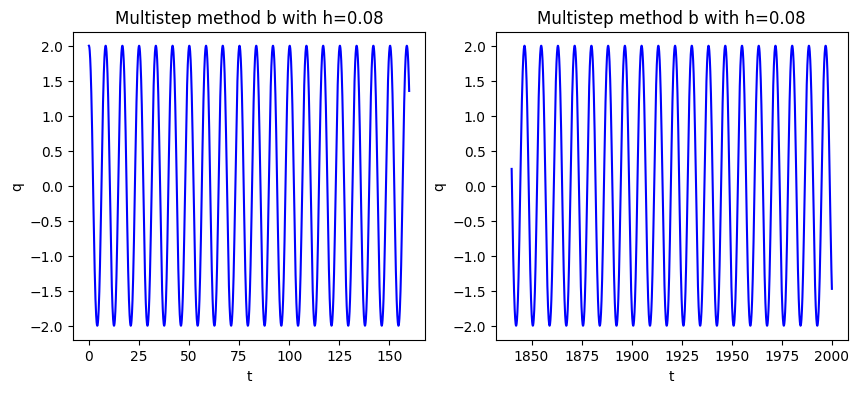

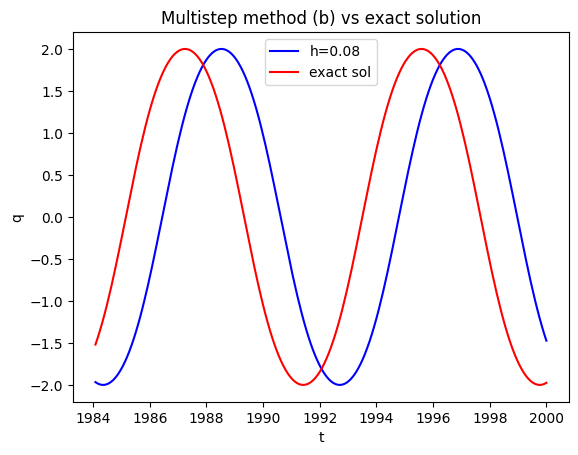

In [48]:
t_vals, p_vals, q_vals = multistep_b(h=0.08, p_0=0, q_0=2, T=2000)

K1 = 2000

fig, (ax1, ax2) = plt.subplots(ncols=2, nrows=1, figsize=(10,4))
ax1.set_xlabel('t')
ax1.set_ylabel('q')
ax1.set_title('Multistep method b with h=0.08')
ax1.plot(t_vals[:K1], q_vals[:K1], color='blue')

ax2.set_xlabel('t')
ax2.set_ylabel('q')
ax2.set_title('Multistep method b with h=0.08')
ax2.plot(t_vals[-K1:], q_vals[-K1:], color='blue')


K2 = -200

# computing exact solution
k = np.sin(1)
m = k**2 
sn, cn, dn, _ = sps.ellipj(t_vals, m)
cd = cn / dn
q_exact = 2 * np.arcsin(k * cd)
p_exact = -2 * k * (1 - m) * sn / (dn**2 * np.sqrt(1 - (k * cd)**2))

fig, ax3 = plt.subplots()
ax3.set_xlabel('t')
ax3.set_ylabel('q')
ax3.plot(t_vals[K2:], q_vals[K2:], color='blue', label='h=0.08')
ax3.plot(t_vals[K2:], q_exact[K2:], color = 'red', label='exact sol')
ax3.set_title('Multistep method (b) vs exact solution')
ax3.legend()


In [49]:
def multistep_c(h, p_0, q_0, T):
    t_vals = np.arange(0, T + h, h)
    q_vals = np.zeros(t_vals.shape)
    p_vals = np.zeros(t_vals.shape)


    # init
    p_vals[0] = p_0
    q_vals[0] = q_0

    for i in range(1, 2):
            p_vals[i] = p_vals[i-1] - 1/2 * h * np.sin(q_vals[i-1]) - 1/2 * h * np.sin(q_vals[i-1] + h * p_vals[i-1])
            q_vals[i] = q_vals[i-1] + 1/2 * h * p_vals[i-1] + 1/2 * h * (p_vals[i-1] - h * np.sin(q_vals[i-1]))

    # multistep
    def F(q1, q, q_1):
         return -q1 + 2 * q - q_1 + (h ** 2)/12 * (-np.sin(q1)- 10 * np.sin(q) - np.sin(q_1))

    def F_prime(q1):
         return -1 - (h ** 2)/12 * np.cos(q1)

    for i in range(2, len(t_vals)):
        q_vals[i] = newtons_method2(F, F_prime, q_vals[i-1], q_vals[i-2], h * q_vals[i-1])

    return t_vals, p_vals, q_vals

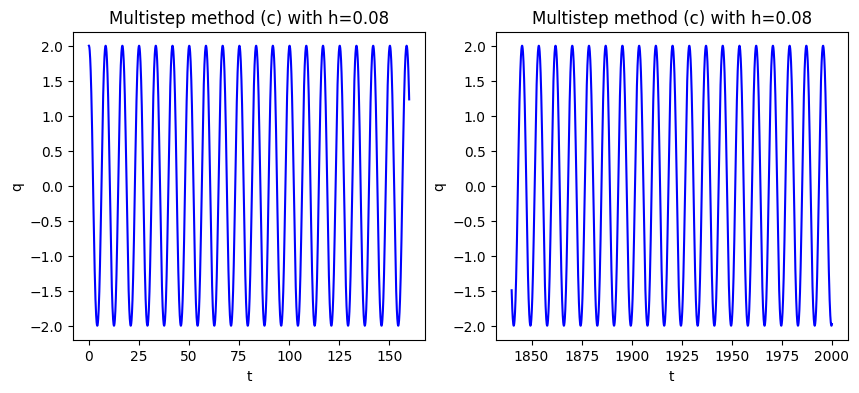

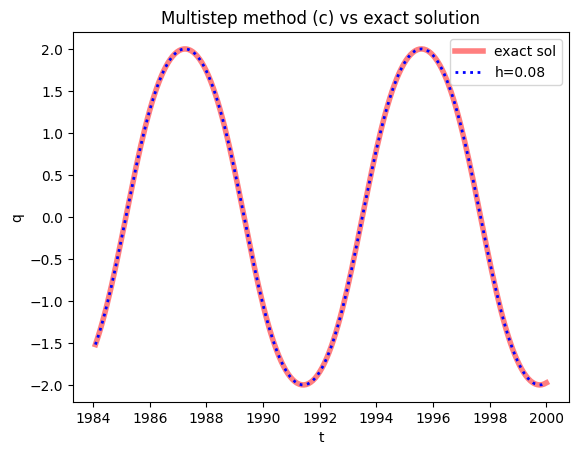

In [50]:
t_vals, p_vals, q_vals = multistep_c(h=0.08, p_0=0, q_0=2, T=2000)

K1 = 2000

fig, (ax1, ax2) = plt.subplots(ncols=2, nrows=1, figsize=(10,4))
ax1.set_xlabel('t')
ax1.set_ylabel('q')
ax1.set_title('Multistep method (c) with h=0.08')
ax1.plot(t_vals[:K1], q_vals[:K1], color='blue')

ax2.set_xlabel('t')
ax2.set_ylabel('q')
ax2.set_title('Multistep method (c) with h=0.08')
ax2.plot(t_vals[-K1:], q_vals[-K1:], color='blue')


K2 = -200

# computing exact solution
k = np.sin(1)
m = k**2 
sn, cn, dn, _ = sps.ellipj(t_vals, m)
cd = cn / dn
q_exact = 2 * np.arcsin(k * cd)
p_exact = -2 * k * (1 - m) * sn / (dn**2 * np.sqrt(1 - (k * cd)**2))

fig, ax3 = plt.subplots()
ax3.set_xlabel('t')
ax3.set_ylabel('q')
ax3.plot(t_vals[K2:], q_exact[K2:], color = 'red', alpha = 0.5, linewidth=4, label='exact sol')
ax3.plot(t_vals[K2:], q_vals[K2:], color='blue', linestyle=':', linewidth=2, label='h=0.08')
ax3.set_title('Multistep method (c) vs exact solution')
ax3.legend()
